# 05 — Hierarchical Clustering and K-Means Robustness | NYC 311 (2023–2025)

**Objective:** Evaluate whether geographic area profiles form robust groups beyond the reporting-volume separation observed in notebook 04. Compare Ward agglomerative clustering with K-Means at **K=2** and **K=3**, using the **full set of areas** and the subset with **at least 30 complaints**.

- Four existing feature representations: Baseline, Balanced, Baseline PCA90, Balanced PCA90.
- No input transformations are fitted here: all matrices and PCA models come from notebooks 02–03.
- Report cluster quality, size imbalance, cross-algorithm agreement, and sensitivity to sparse areas.
- Do not equate clusters with verified infrastructure condition or hotspots.

**Important methodological caution:** The >=30 analysis reuses scaling and PCA fitted on *all* areas. This is a **fixed-transformation sensitivity check**, not an independently refitted training pipeline. An independent preprocessing refit would be a separate future experiment.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")

import sys
from pathlib import Path
import itertools
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "config" / "config.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate config/config.py; open the project root or notebooks folder")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from config.config import PROCESSED_DATA_DIR, OUTPUT_DIR, PCA_DIR

TABLE_DIR = OUTPUT_DIR / "tables" / "hierarchical"
FIG_DIR = OUTPUT_DIR / "figures" / "hierarchical"
MODEL_DIR = PROJECT_ROOT / "models" / "hierarchical"
for directory in (TABLE_DIR, FIG_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)
SEED = 42
MIN_SUPPORT = 30  # sensitivity threshold, NOT a validated urban-service cutoff
K_VALUES = (2, 3)
print("Project root:", PROJECT_ROOT)
print("Experiment: Ward vs K-Means | K=2,3 | full vs >=30 reports")

Project root: d:\Urban-Infrastructure-Pulse-Intelligence
Experiment: Ward vs K-Means | K=2,3 | full vs >=30 reports


## 1. Load and validate the existing modeling inputs

Use exactly the same preprocessing outputs and fitted PCA models as notebooks 02–04. Validate row order, features, PCA metadata, and support counts. No hardcoded number of areas or numeric features.

In [2]:
paths = {
    "Baseline": PROCESSED_DATA_DIR / "kmeans_pca_input.csv",
    "Balanced": PROCESSED_DATA_DIR / "kmeans_pca_input_balanced.csv",
    "Original": PROCESSED_DATA_DIR / "selected_modeling_features.csv",
}
for name, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name} input missing: {path}. Run notebooks 02–03 first.")
frames = {name: pd.read_csv(path) for name, path in paths.items()}
for name, frame in frames.items():
    if "area_id" not in frame or frame["area_id"].isna().any() or frame["area_id"].duplicated().any():
        raise ValueError(f"{name}: missing, null, or duplicate area_id")
ids = frames["Baseline"]["area_id"].astype(str).to_numpy()
for name in ("Balanced", "Original"):
    if not np.array_equal(ids, frames[name]["area_id"].astype(str).to_numpy()):
        raise ValueError(f"{name}: area IDs are not aligned with Baseline")
feature_cols = frames["Baseline"].columns.drop("area_id").tolist()
if not feature_cols or feature_cols != frames["Balanced"].columns.drop("area_id").tolist():
    raise ValueError("Baseline and Balanced numerical feature columns do not match")
if "total_complaints" not in frames["Original"].columns:
    raise ValueError("Original features are missing total_complaints")
source = frames["Original"].copy()
counts = pd.to_numeric(source["total_complaints"], errors="coerce")
if not np.isfinite(counts.to_numpy()).all() or (counts <= 0).any():
    raise ValueError("total_complaints contains missing, nonfinite, or nonpositive values")
retain_mask = counts.ge(MIN_SUPPORT).to_numpy()
if retain_mask.sum() <= max(K_VALUES) + 1:
    raise ValueError("Too few higher-support areas for K=2 and K=3")

X_by_rep = {}
for name in ("Baseline", "Balanced"):
    X = frames[name][feature_cols]
    if X.select_dtypes(exclude="number").shape[1] or not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError(f"{name}: nonnumeric/missing/infinite inputs")
    X_by_rep[name] = X.to_numpy(dtype=float)

pca_info = []
for name in ("Baseline", "Balanced"):
    model_path = PCA_DIR / f"{name.lower()}_pca_model.joblib"
    if not model_path.is_file():
        raise FileNotFoundError(f"Missing fitted PCA model: {model_path}; run notebook 03")
    payload = joblib.load(model_path)  # trusted artifacts generated locally in notebook 03
    if payload.get("feature_order") != feature_cols or payload.get("area_count_at_fit") != len(ids):
        raise ValueError(f"{name} PCA model is stale: feature order or area count mismatch")
    pca = payload["pca"]
    explained = np.asarray(pca.explained_variance_ratio_, dtype=float)
    n90 = int(np.searchsorted(np.cumsum(explained), 0.90) + 1)
    X_by_rep[f"{name} PCA90"] = pca.transform(X_by_rep[name])[:, :n90]
    pca_info.append({"representation": f"{name} PCA90", "components": n90,
                     "variance_retained": float(explained[:n90].sum())})

print("FULL INPUT VALIDATION PASSED")
print("Total areas:", len(ids))
print("Areas with >=30 complaints:", int(retain_mask.sum()))
print("Excluded low-support areas:", int((~retain_mask).sum()))
print("Numerical features:", len(feature_cols))
display(pd.DataFrame(pca_info).round(4))

FULL INPUT VALIDATION PASSED
Total areas: 238
Areas with >=30 complaints: 191
Excluded low-support areas: 47
Numerical features: 19


c:\Users\Administrator\miniconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Administrator\miniconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


,representation,components,variance_retained
0,Baseline PCA90,2,0.9014
1,Balanced PCA90,5,0.9069


## 2. Compare K-Means and Ward hierarchical clustering

Ward's method merges clusters to minimize within-cluster variance using **Euclidean distance**. It is not a geographic-distance clustering method. Evaluate each K and data representation on both area subsets. Scores are best compared **within the same representation and support subset**, not treated as universal measures across differently scaled spaces.

In [3]:
def score_partition(X, labels):
    labels = np.asarray(labels, dtype=int)
    sizes = np.bincount(labels)
    if sizes.min() == 0 or len(sizes) < 2 or len(sizes) >= len(labels):
        raise ValueError("Invalid clustering partition for internal scoring")
    return {
        "silhouette": float(silhouette_score(X, labels)),
        "davies_bouldin": float(davies_bouldin_score(X, labels)),
        "calinski_harabasz": float(calinski_harabasz_score(X, labels)),
        "min_cluster_size": int(sizes.min()),
        "max_cluster_size": int(sizes.max()),
        "largest_cluster_pct": 100.0 * float(sizes.max()) / len(labels),
        "cluster_sizes": " / ".join(map(str, sorted(sizes.tolist(), reverse=True))),
    }

partitions = {}
models = {}
records = []
for representation, X_full in X_by_rep.items():
    for subset_name, mask in (("Full", np.ones(len(ids), dtype=bool)),
                              ("Support30", retain_mask)):
        X = X_full[mask]
        for k in K_VALUES:
            for algorithm in ("KMeans", "Ward"):
                if algorithm == "KMeans":
                    model = KMeans(n_clusters=k, random_state=SEED, n_init=50, max_iter=500)
                else:
                    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
                labels = model.fit_predict(X)
                key = (representation, subset_name, algorithm, k)
                partitions[key] = np.asarray(labels)
                models[key] = model
                records.append({"representation": representation, "subset": subset_name,
                                "areas": len(X), "algorithm": algorithm, "k": k,
                                **score_partition(X, labels)})

comparison = pd.DataFrame(records).sort_values(["subset", "representation", "k", "algorithm"])
comparison.to_csv(TABLE_DIR / "clustering_method_comparison.csv", index=False)
print("All method comparisons calculated:", len(comparison))
display(comparison[["representation", "subset", "algorithm", "k", "areas",
                    "silhouette", "davies_bouldin", "cluster_sizes", "largest_cluster_pct"]].round(4))

All method comparisons calculated: 32


,representation,subset,algorithm,k,areas,silhouette,davies_bouldin,cluster_sizes,largest_cluster_pct
8,Balanced,Full,KMeans,2,238,0.6745,0.6821,193 / 45,81.0924
9,Balanced,Full,Ward,2,238,0.6705,0.6742,196 / 42,82.3529
10,Balanced,Full,KMeans,3,238,0.5809,1.0820,174 / 43 / 21,73.1092
11,Balanced,Full,Ward,3,238,0.5772,1.1083,173 / 42 / 23,72.6891
24,Balanced PCA90,Full,KMeans,2,238,0.7164,0.5690,193 / 45,81.0924
25,Balanced PCA90,Full,Ward,2,238,0.7130,0.5766,194 / 44,81.5126
26,Balanced PCA90,Full,KMeans,3,238,0.6335,0.9031,174 / 43 / 21,73.1092
27,Balanced PCA90,Full,Ward,3,238,0.6292,0.8986,174 / 44 / 20,73.1092
0,Baseline,Full,KMeans,2,238,0.7300,0.5154,193 / 45,81.0924
1,Baseline,Full,Ward,2,238,0.7297,0.5061,195 / 43,81.9328


## 3. Agreement and sensitivity to low-support areas

Adjusted Rand Index (ARI) compares partitions while ignoring arbitrary cluster label numbers. Compare K-Means to Ward for the same subset, then compare full-area assignments to refitted higher-support assignments for each method.

In [4]:
agreement_rows = []
for rep in X_by_rep:
    for subset in ("Full", "Support30"):
        for k in K_VALUES:
            a = partitions[(rep, subset, "KMeans", k)]
            b = partitions[(rep, subset, "Ward", k)]
            agreement_rows.append({"representation": rep, "subset": subset, "k": k,
                                   "comparison": "KMeans_vs_Ward", "ari": adjusted_rand_score(a, b)})
    for algorithm in ("KMeans", "Ward"):
        for k in K_VALUES:
            full = partitions[(rep, "Full", algorithm, k)][retain_mask]
            support = partitions[(rep, "Support30", algorithm, k)]
            agreement_rows.append({"representation": rep, "subset": "Full_vs_Support30", "k": k,
                                   "comparison": f"{algorithm}_full_vs_subset_refit",
                                   "ari": adjusted_rand_score(full, support)})

agreement = pd.DataFrame(agreement_rows)
agreement.to_csv(TABLE_DIR / "clustering_agreement_and_support_sensitivity.csv", index=False)
display(agreement.round(4))

,representation,subset,k,comparison,ari
0,Baseline,Full,2,KMeans_vs_Ward,0.9604
1,Baseline,Full,3,KMeans_vs_Ward,1.0000
2,Baseline,Support30,2,KMeans_vs_Ward,1.0000
3,Baseline,Support30,3,KMeans_vs_Ward,0.8971
4,Baseline,Full_vs_Support30,2,KMeans_full_vs_subset_refit,0.0927
5,Baseline,Full_vs_Support30,3,KMeans_full_vs_subset_refit,0.8863
6,Baseline,Full_vs_Support30,2,Ward_full_vs_subset_refit,0.0927
7,Baseline,Full_vs_Support30,3,Ward_full_vs_subset_refit,0.9868
8,Balanced,Full,2,KMeans_vs_Ward,0.9405
9,Balanced,Full,3,KMeans_vs_Ward,0.9813


## 4. Original-unit cluster profiles and complaint-type composition

Interpret clusters on **original, unscaled features**. Cluster labels are arbitrary; a cluster numbered 0 in one experiment need not correspond to cluster 0 in another. The profiles below focus on the higher-support areas, where interpretations are less dominated by one-complaint observations.

In [5]:
profile_columns = [c for c in ["total_complaints", "active_months", "monthly_cv",
                  "repeated_complaint_rate", "persistent_complaint_rate", "avg_recurrence_span_days"]
                   if c in source.columns]
share_columns = sorted(c for c in source.columns if c.startswith("share_"))
if not profile_columns:
    raise ValueError("No original-unit explanatory features found")
profiles = []
assignments = []
for rep in X_by_rep:
    for algorithm in ("KMeans", "Ward"):
        for k in K_VALUES:
            labels = partitions[(rep, "Support30", algorithm, k)]
            subset_df = source.loc[retain_mask, ["area_id", *profile_columns, *share_columns]].copy()
            subset_df["cluster_id"] = labels
            for cid, chunk in subset_df.groupby("cluster_id"):
                entry = {"representation": rep, "subset": "Support30", "algorithm": algorithm,
                         "k": k, "cluster_id": int(cid), "areas": len(chunk)}
                entry.update({f"median_{c}": float(chunk[c].median()) for c in profile_columns})
                if share_columns:
                    top = chunk[share_columns].mean().sort_values(ascending=False).head(3)
                    for rank, (feature, value) in enumerate(top.items(), start=1):
                        entry[f"top_category_{rank}"] = feature.removeprefix("share_")
                        entry[f"top_category_share_{rank}"] = float(value)
                profiles.append(entry)
            assignments.append(pd.DataFrame({"area_id": ids[retain_mask],
                         "representation": rep, "algorithm": algorithm,
                         "k": k, "cluster_id": labels}))
profile_df = pd.DataFrame(profiles).sort_values(["representation", "algorithm", "k", "cluster_id"])
assignment_df = pd.concat(assignments, ignore_index=True)
profile_df.to_csv(TABLE_DIR / "higher_support_cluster_profiles.csv", index=False)
assignment_df.to_csv(TABLE_DIR / "higher_support_cluster_assignments.csv", index=False)
display(profile_df[["representation", "algorithm", "k", "cluster_id", "areas",
                    *[f"median_{c}" for c in profile_columns]]].round(3))

,representation,algorithm,k,cluster_id,areas,median_total_complaints,median_active_months,median_monthly_cv,median_repeated_complaint_rate,median_persistent_complaint_rate,median_avg_recurrence_span_days
10,Balanced,KMeans,2,0,174,3473.5,36.0,0.226,0.662,0.359,689.436
11,Balanced,KMeans,2,1,17,89.0,32.0,1.092,0.833,0.704,715.009
12,Balanced,KMeans,3,0,9,94.0,32.0,0.894,0.532,0.176,648.632
13,Balanced,KMeans,3,1,172,3480.5,36.0,0.226,0.663,0.362,689.945
14,Balanced,KMeans,3,2,10,99.0,25.0,1.337,0.906,0.798,792.465
15,Balanced,Ward,2,0,18,91.5,32.0,1.038,0.797,0.617,716.289
16,Balanced,Ward,2,1,173,3476.0,36.0,0.226,0.662,0.356,689.407
17,Balanced,Ward,3,0,173,3476.0,36.0,0.226,0.662,0.356,689.407
18,Balanced,Ward,3,1,11,116.0,27.0,1.336,0.886,0.767,734.186
19,Balanced,Ward,3,2,7,89.0,32.0,0.985,0.484,0.176,703.147


## 5. How much of each full-data cluster is low-support?

This diagnostic avoids interpreting low-support clusters as proven geographic need categories. Comparisons use the same **full-data** partitions, not refitted partitions.

In [6]:
diagnostics = []
for rep in X_by_rep:
    for algorithm in ("KMeans", "Ward"):
        for k in K_VALUES:
            labels = partitions[(rep, "Full", algorithm, k)]
            for cid in np.unique(labels):
                member = labels == cid
                n_low = int((member & ~retain_mask).sum())
                diagnostics.append({"representation": rep, "algorithm": algorithm,
                                    "k": k, "cluster_id": int(cid),
                                    "areas": int(member.sum()), "low_support_areas": n_low,
                                    "low_support_pct": 100 * n_low / int(member.sum())})
low_support_diagnostics = pd.DataFrame(diagnostics)
low_support_diagnostics.to_csv(TABLE_DIR / "full_cluster_low_support_diagnostics.csv", index=False)
display(low_support_diagnostics.round(2))

,representation,algorithm,k,cluster_id,areas,low_support_areas,low_support_pct
0,Baseline,KMeans,2,0,193,3,1.55
1,Baseline,KMeans,2,1,45,44,97.78
2,Baseline,KMeans,3,0,174,0,0.00
3,Baseline,KMeans,3,1,43,42,97.67
4,Baseline,KMeans,3,2,21,5,23.81
5,Baseline,Ward,2,0,195,5,2.56
6,Baseline,Ward,2,1,43,42,97.67
7,Baseline,Ward,3,0,43,42,97.67
8,Baseline,Ward,3,1,21,5,23.81
9,Baseline,Ward,3,2,174,0,0.00


## 6. Dendrograms for Ward hierarchical clustering

A truncated Ward dendrogram shows the final cluster merges for the **191-area-or-similar** higher-support subset. The dendrogram illustrates **feature-space dissimilarity**, not geographic distance. Because the tree depends on input scaling, review Baseline and Balanced separately.

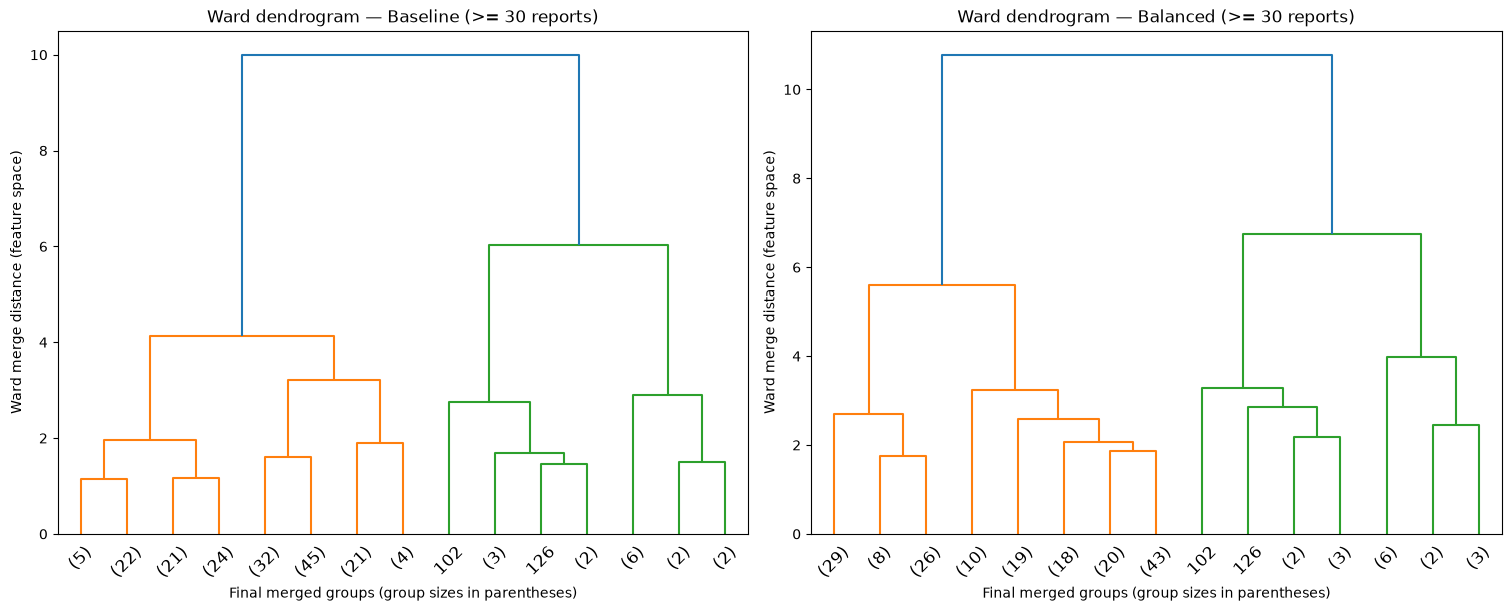

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, rep in zip(axes, ("Baseline", "Balanced")):
    Z = linkage(X_by_rep[rep][retain_mask], method="ward", metric="euclidean", optimal_ordering=False)
    dendrogram(Z, truncate_mode="lastp", p=min(15, retain_mask.sum()),
               show_leaf_counts=True, leaf_rotation=45, ax=ax)
    ax.set_title(f"Ward dendrogram — {rep} (>= {MIN_SUPPORT} reports)")
    ax.set_xlabel("Final merged groups (group sizes in parentheses)")
    ax.set_ylabel("Ward merge distance (feature space)")
    joblib.dump({"linkage": Z, "representation": rep, "support_threshold": MIN_SUPPORT,
                 "area_ids": ids[retain_mask].tolist(),
                 "warning": "Linkage is for description; Ward does not predict unseen areas"},
                MODEL_DIR / f"{rep.lower()}_support30_ward_linkage.joblib")
fig.savefig(FIG_DIR / "ward_dendrograms_support30.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Visual diagnostic: K-Means vs Ward on two PCA axes

Visualization uses PCA components fitted in notebook 03. Only two PCs are displayed; clusters were computed using the full representation indicated in each panel, not necessarily only the displayed two PCs.

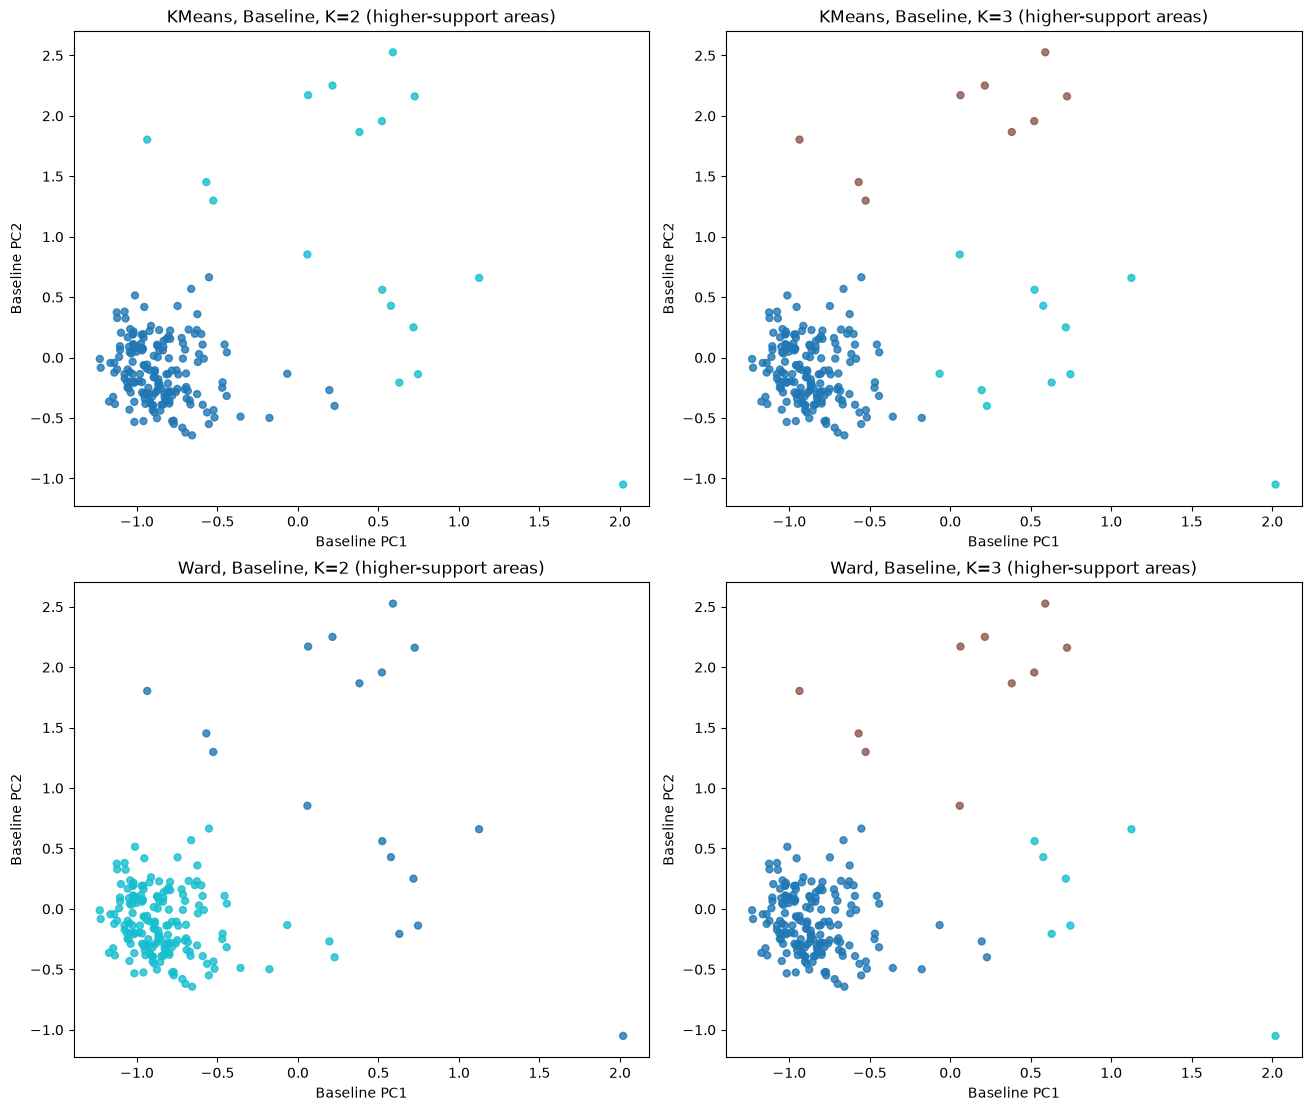

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
coords = X_by_rep["Baseline PCA90"][retain_mask]
# If Baseline PCA90 has two or more PCs, display them. Otherwise use the fitted Baseline PCA transform.
if coords.shape[1] < 2:
    payload = joblib.load(PCA_DIR / "baseline_pca_model.joblib")
    coords = payload["pca"].transform(X_by_rep["Baseline"])[retain_mask, :2]
for row, algorithm in enumerate(("KMeans", "Ward")):
    for column, k in enumerate(K_VALUES):
        ax = axes[row, column]
        labels = partitions[("Baseline", "Support30", algorithm, k)]
        ax.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="tab10", s=25, alpha=0.8)
        ax.set_title(f"{algorithm}, Baseline, K={k} (higher-support areas)")
        ax.set_xlabel("Baseline PC1")
        ax.set_ylabel("Baseline PC2")
fig.savefig(FIG_DIR / "kmeans_ward_pca_projection_support30.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Reproducible decision audit

- **K=2 vs K=3:** favor neither automatically; inspect silhouette, Davies–Bouldin, cluster sizes, and original-unit profiles.
- **K-Means vs Ward:** high ARI indicates that groupings are not unique to the K-Means algorithm; disagreement identifies algorithm sensitivity.
- **Full vs higher-support:** large ARI changes or cluster-size shifts indicate sensitivity to sparse areas.
- **Reporting versus infrastructure:** a stable reporting-profile cluster still does not establish a confirmed physical hotspot or service blind spot.
- **Future work:** refit preprocessing on higher-support areas as a separate experiment; use geospatial clustering on verified coordinates for actual spatial hotspots.

All outputs are exploratory candidates. No final clustering model is selected automatically.

In [9]:
assert len(comparison) == len(X_by_rep) * 2 * len(K_VALUES) * 2
assert (comparison["min_cluster_size"] >= 1).all()
assert comparison["silhouette"].between(-1, 1).all()
assert agreement["ari"].between(-1, 1).all()
assert len(assignment_df) == int(retain_mask.sum()) * len(X_by_rep) * 2 * len(K_VALUES)
assert all((TABLE_DIR / x).is_file() for x in [
    "clustering_method_comparison.csv",
    "clustering_agreement_and_support_sensitivity.csv",
    "higher_support_cluster_profiles.csv",
    "higher_support_cluster_assignments.csv",
    "full_cluster_low_support_diagnostics.csv",
])

print("ALL HIERARCHICAL / K-MEANS ROBUSTNESS INTEGRITY CHECKS PASSED")
print("Full areas:", len(ids), "| Higher-support areas:", int(retain_mask.sum()))
print("Tables:", TABLE_DIR)
print("Figures:", FIG_DIR)
print("Linkage artifacts:", MODEL_DIR)
print("Important: these are candidate reporting-profile partitions; no final K/model chosen.")

ALL HIERARCHICAL / K-MEANS ROBUSTNESS INTEGRITY CHECKS PASSED
Full areas: 238 | Higher-support areas: 191
Tables: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\hierarchical
Figures: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\figures\hierarchical
Linkage artifacts: d:\Urban-Infrastructure-Pulse-Intelligence\models\hierarchical
Important: these are candidate reporting-profile partitions; no final K/model chosen.
